# Detect, then Adapt: Shift-Gated Test-Time Adaptation for Traffic-Sign Recognition

A ResNet-18 is trained on clean GTSRB images. A **frozen** copy watches incoming unlabeled windows and scores them with an entropy KS test. When the score stays above a threshold calibrated on clean validation streams, a gate opens and the **deployed** copy adapts with TENT. When the stream looks clean again, the deployed model is reset to its source weights.

We compare four policies (never adapt, always adapt, detector-gated TENT and oracle-gated TENT) plus a gated BatchNorm baseline on five streams (E1–E5). Ablations cover entropy-KS vs. BBSDs, the gate's persistence settings (m, k), and correlated vs. shuffled streams.

**Run:** Colab → Runtime → Change runtime type → T4 GPU, then *Run all*. It takes roughly 30–40 minutes end to end. Everything is written to `artifacts/` and zipped at the end. The last cell prints all the numbers needed for the report.

## 0. Setup
All settings the plan asks us to record (seeds, split, stream settings, τ, m/k) are kept in `CFG` and saved to `artifacts/config.json`.

In [ ]:
import os, re, copy, json, time, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from scipy import stats
from scipy.ndimage import gaussian_filter
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ART = "artifacts"
os.makedirs(ART, exist_ok=True)

CFG = {
    "seed": SEED,
    "img_size": 48,
    "split_fractions": {"train": 0.6, "val": 0.2, "test": 0.2},  # by track, within each class
    "epochs": 15,
    "batch_size": 128,
    "lr": 1e-3,
    "weight_decay": 5e-4,
    "window": 64,               # frames per stream window (also the TENT batch size)
    "n_calib_streams": 20,      # clean validation streams per ordering, used to set tau
    "tau_quantile": 0.95,
    "burst_severity": 2.0,      # severity of tunnel/fog bursts (levels 1-3)
    "e5_max_severity": 3.0,
    "tent_lr": 1e-3,            # TENT's default Adam learning rate, not tuned
    "bn_momentum": 0.1,
    "gate_grid": [[m, k] for m in (1, 2, 3) for k in (1, 2, 3)],
    "stream_seeds": [0, 1, 2],
    "collapse": {"excess_concentration": 0.3, "max_acc": 0.3},
}
IMG, W = CFG["img_size"], CFG["window"]
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu130


## 1. Data: download, metadata audit and track-aware split
GTSRB training images come in *tracks*: about 30 consecutive frames of the same physical sign. Splitting by image would put near-duplicates in both train and test, so we split by track inside each class. The validation tracks are split once more. **ref** tracks give the detector its clean reference distribution. **calib** tracks build the clean streams used to set τ and to choose m and k.

In [ ]:
train_raw = torchvision.datasets.GTSRB(root="data", split="train", download=True)
test_raw = torchvision.datasets.GTSRB(root="data", split="test", download=True)
print(f"official train images: {len(train_raw)} | official test images: {len(test_raw)}")

# Training files are stored as <class>/<track>_<frame>.ppm, so (class, track) identifies one sign.
rows, unmatched = [], 0
for path, label in train_raw._samples:
    m = re.match(r"^(\d+)_(\d+)\.\w+$", os.path.basename(path))
    if m is None:
        unmatched += 1
        continue
    rows.append({"path": path, "label": label,
                 "track": f"{label:02d}_{m.group(1)}", "frame": int(m.group(2))})
assert unmatched == 0, f"{unmatched} files do not follow the track naming pattern"

meta = pd.DataFrame(rows).sort_values(["label", "track", "frame"]).reset_index(drop=True)
frames_per_track = meta.groupby("track").size()
print(f"classes: {meta.label.nunique()} | tracks: {meta.track.nunique()} | frames per track: "
      f"min {frames_per_track.min()}, median {int(frames_per_track.median())}, max {frames_per_track.max()}")

100%|██████████| 187M/187M [00:22<00:00, 8.45MB/s]
100%|██████████| 89.0M/89.0M [00:08<00:00, 10.8MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 213kB/s]


official train images: 26640 | official test images: 12630
classes: 43 | tracks: 888 | frames per track: min 30, median 30, max 30


In [ ]:
def load_resized(paths):
    out = np.empty((len(paths), IMG, IMG, 3), dtype=np.uint8)
    for i, p in enumerate(tqdm(paths, desc="loading", mininterval=2)):
        with Image.open(p) as im:
            out[i] = np.asarray(im.convert("RGB").resize((IMG, IMG), Image.BILINEAR))
    return out

# Row i of X_all is row i of meta.
X_all, y_all = load_resized(meta.path.tolist()), meta.label.to_numpy()
X_official = load_resized([p for p, _ in test_raw._samples])
y_official = np.array([label for _, label in test_raw._samples])

rng = np.random.default_rng(SEED)
role = {}
for label, g in meta.groupby("label"):
    tracks = rng.permutation(g.track.unique())
    n = len(tracks)
    n_tr = int(round(CFG["split_fractions"]["train"] * n))
    n_va = max(1, int(round(CFG["split_fractions"]["val"] * n)))
    for t in tracks[:n_tr]:
        role[t] = "train"
    for j, t in enumerate(tracks[n_tr:n_tr + n_va]):
        role[t] = "ref" if j % 2 == 0 else "calib"
    for t in tracks[n_tr + n_va:]:
        role[t] = "test"
meta["role"] = meta.track.map(role)
assert meta.groupby("track").role.nunique().max() == 1  # no track crosses partitions

ROLES = ["train", "ref", "calib", "test"]
IDX = {r: meta.index[meta.role == r].to_numpy() for r in ROLES}
# Frame indices grouped by track, frames in temporal order. Streams are built from these.
TRACKS = {r: [g.index.to_numpy() for _, g in meta[meta.role == r].groupby("track")] for r in ROLES}

split_table = (meta.groupby("role")
               .agg(images=("label", "size"), tracks=("track", "nunique"), classes=("label", "nunique"))
               .loc[ROLES])
print(split_table)
split_table.to_csv(f"{ART}/split_summary.csv")

# Per-channel normalisation is fitted on the source training images only.
Xtr = X_all[IDX["train"]]
s1, s2, npx = np.zeros(3), np.zeros(3), 0
for i in range(0, len(Xtr), 2000):
    chunk = Xtr[i:i + 2000].reshape(-1, 3).astype(np.float64) / 255
    s1 += chunk.sum(0)
    s2 += (chunk ** 2).sum(0)
    npx += len(chunk)
MEAN = s1 / npx
STD = np.sqrt(s2 / npx - MEAN ** 2)
CFG["norm_mean"], CFG["norm_std"] = MEAN.round(4).tolist(), STD.round(4).tolist()
print("normalisation mean", MEAN.round(4), "std", STD.round(4))

loading:   0%|          | 0/26640 [00:00<?, ?it/s]

loading:   0%|          | 0/12630 [00:00<?, ?it/s]

       images  tracks  classes
role                          
train   15990     533       43
ref      2970      99       43
calib    2310      77       33
test     5370     179       43
normalisation mean [0.338  0.3093 0.3186] std [0.272  0.2599 0.2662]


## 2. Shifts: tunnel darkness and fog
Both corruptions have severity levels 1–3. Severity 0 is the clean image, and values in between are interpolated, so E5 can ramp the fog up smoothly. **Pilot 2** is the image grid below: the shifts should look plausible, and the sign should still be identifiable.

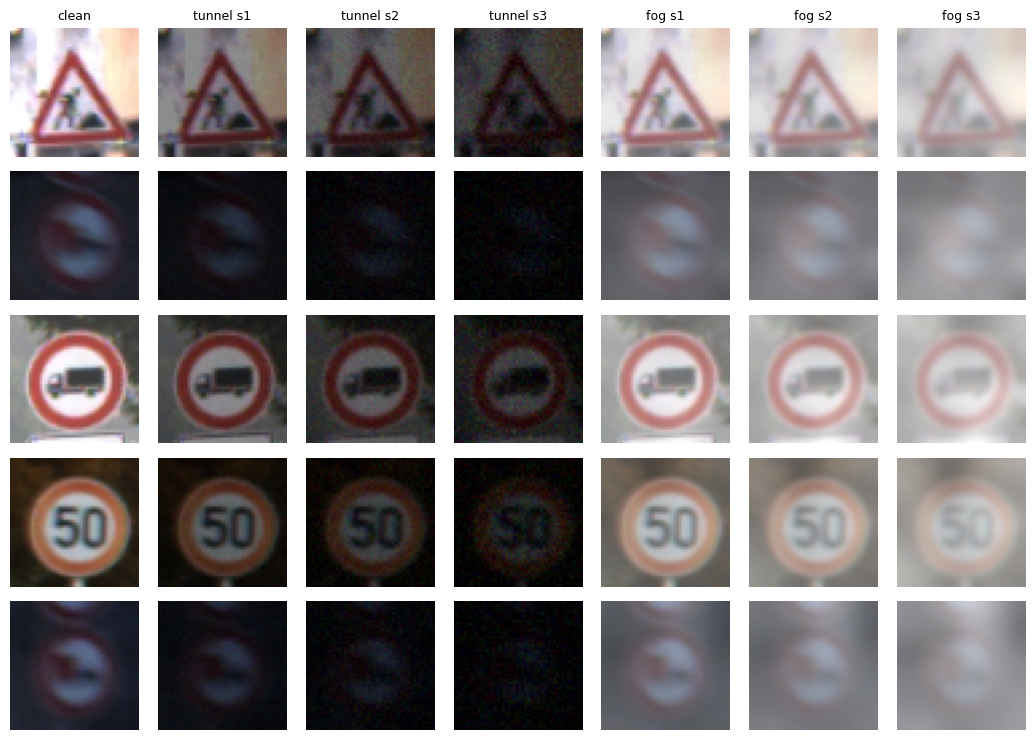

In [ ]:
LEVELS = [0, 1, 2, 3]
TUNNEL = {"brightness": [1.0, 0.55, 0.38, 0.25], "gamma": [1.0, 1.15, 1.3, 1.5],
          "noise": [0.0, 0.01, 0.02, 0.03], "blur": [0.0, 0.3, 0.5, 0.7]}
FOG = {"alpha": [0.0, 0.35, 0.5, 0.65], "blur": [0.0, 0.5, 0.8, 1.1]}
CFG["tunnel_params"], CFG["fog_params"] = TUNNEL, FOG

def _level(table, key, sev):
    return float(np.interp(sev, LEVELS, table[key]))

def _blur(x, sigma):
    return gaussian_filter(x, sigma=(0, sigma, sigma, 0)) if sigma > 0 else x

def _to_uint8(x):
    return (np.clip(x, 0, 1) * 255 + 0.5).astype(np.uint8)

def tunnel_darkness(X, sev, rng):
    """Low light: gamma and brightness drop, slight blur, then sensor noise."""
    x = X.astype(np.float32) / 255
    x = _level(TUNNEL, "brightness", sev) * x ** _level(TUNNEL, "gamma", sev)
    x = _blur(x, _level(TUNNEL, "blur", sev))
    x = x + rng.normal(0, _level(TUNNEL, "noise", sev), x.shape).astype(np.float32)
    return _to_uint8(x)

def fog(X, sev, rng):
    """Blur, then blend towards a bright and slightly uneven haze."""
    x = _blur(X.astype(np.float32) / 255, _level(FOG, "blur", sev))
    haze = gaussian_filter(rng.normal(size=(len(x), IMG, IMG, 1)).astype(np.float32), sigma=(0, 6, 6, 0))
    haze = 0.8 + 0.08 * haze / (haze.std(axis=(1, 2, 3), keepdims=True) + 1e-6)
    a = _level(FOG, "alpha", sev)
    return _to_uint8((1 - a) * x + a * haze)

def corrupt(X, cond, sev, rng):
    if cond == "clean" or sev <= 0:
        return X.copy()
    return {"tunnel": tunnel_darkness, "fog": fog}[cond](X, sev, rng)

show = np.random.default_rng(SEED).choice(IDX["calib"], 5, replace=False)
grid_conds = [("clean", 0)] + [("tunnel", s) for s in (1, 2, 3)] + [("fog", s) for s in (1, 2, 3)]
fig, axes = plt.subplots(len(show), len(grid_conds), figsize=(1.5 * len(grid_conds), 1.5 * len(show)))
for c, (cond, sev) in enumerate(grid_conds):
    imgs = corrupt(X_all[show], cond, sev, np.random.default_rng(0))
    for r in range(len(show)):
        axes[r, c].imshow(imgs[r])
        axes[r, c].axis("off")
    axes[0, c].set_title("clean" if sev == 0 else f"{cond} s{sev}", fontsize=9)
plt.tight_layout()
plt.savefig(f"{ART}/fig_shift_examples.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Source classifier: ResNet-18 on clean images
The ImageNet stem is too aggressive for 48×48 inputs, so it is replaced with a 3×3 stride-1 convolution and the max-pool is dropped. Augmentation is geometric only: no flips, because they change a sign's meaning, and no colour jitter, so the source model never sees photometric shifts. The checkpoint with the best clean validation accuracy is kept. **Pilot 1**: reasonable validation accuracy and a saved loss curve.

In [ ]:
MEAN_C = torch.tensor(MEAN, dtype=torch.float32).view(3, 1, 1)
STD_C = torch.tensor(STD, dtype=torch.float32).view(3, 1, 1)
MEAN_T, STD_T = MEAN_C.unsqueeze(0).to(device), STD_C.unsqueeze(0).to(device)

def to_input(X):
    """uint8 images (N, H, W, 3) -> normalised float tensor on the device."""
    x = torch.from_numpy(np.ascontiguousarray(X)).to(device).permute(0, 3, 1, 2).float().div_(255)
    return (x - MEAN_T) / STD_T

class SignDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = X, y, augment
        self.aug = T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1),
                                  interpolation=T.InterpolationMode.BILINEAR)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255
        if self.augment:
            x = self.aug(x)
        return (x - MEAN_C) / STD_C, int(self.y[i])

def build_resnet18(num_classes=43):
    model = torchvision.models.resnet18(weights=None, num_classes=num_classes)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, 100 * correct / n

val_idx = np.concatenate([IDX["ref"], IDX["calib"]])
train_loader = DataLoader(SignDataset(X_all[IDX["train"]], y_all[IDX["train"]], augment=True),
                          batch_size=CFG["batch_size"], shuffle=True, num_workers=2,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(SignDataset(X_all[val_idx], y_all[val_idx]), batch_size=512, num_workers=2)

net = build_resnet18().to(device)
opt = torch.optim.AdamW(net.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"])
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

log, best_acc = [], -1.0
for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    net.train()
    loss_sum, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss = F.cross_entropy(net(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        loss_sum += loss.item() * len(y)
        n += len(y)
    sched.step()
    val_loss, val_acc = evaluate(net, val_loader)
    log.append({"epoch": epoch, "train_loss": loss_sum / n, "val_loss": val_loss, "val_acc": val_acc,
                "seconds": time.time() - t0})
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(net.state_dict(), f"{ART}/resnet18_source.pt")
    print(f"epoch {epoch:2d} | train loss {loss_sum / n:.4f} | val loss {val_loss:.4f} | "
          f"val acc {val_acc:.2f}% | {time.time() - t0:.0f}s")

train_log = pd.DataFrame(log)
train_log.to_csv(f"{ART}/training_log.csv", index=False)
del net

source_model = build_resnet18().to(device)
source_model.load_state_dict(torch.load(f"{ART}/resnet18_source.pt", map_location=device))
source_model.eval().requires_grad_(False)
best_epoch = int(train_log.val_acc.idxmax()) + 1
print(f"\nPilot 1: best clean validation accuracy {best_acc:.2f}% at epoch {best_epoch}")

epoch  1 | train loss 2.1856 | val loss 1.7352 | val acc 48.43% | 19s
epoch  2 | train loss 0.6275 | val loss 0.9456 | val acc 72.29% | 17s
epoch  3 | train loss 0.1058 | val loss 0.5272 | val acc 86.38% | 17s
epoch  4 | train loss 0.0471 | val loss 0.4450 | val acc 88.20% | 18s
epoch  5 | train loss 0.0184 | val loss 0.3266 | val acc 91.57% | 18s
epoch  6 | train loss 0.0109 | val loss 0.2371 | val acc 94.03% | 18s
epoch  7 | train loss 0.0050 | val loss 0.2213 | val acc 95.19% | 18s
epoch  8 | train loss 0.0039 | val loss 0.2270 | val acc 94.73% | 18s
epoch  9 | train loss 0.0012 | val loss 0.1924 | val acc 95.76% | 18s
epoch 10 | train loss 0.0007 | val loss 0.1963 | val acc 95.87% | 18s
epoch 11 | train loss 0.0006 | val loss 0.1933 | val acc 95.87% | 17s
epoch 12 | train loss 0.0005 | val loss 0.1952 | val acc 95.89% | 17s
epoch 13 | train loss 0.0005 | val loss 0.1941 | val acc 96.04% | 17s
epoch 14 | train loss 0.0004 | val loss 0.1911 | val acc 96.02% | 17s
epoch 15 | train los

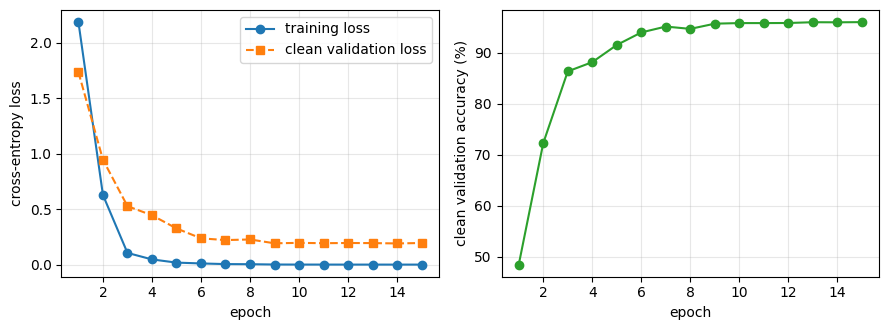

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(train_log.epoch, train_log.train_loss, "o-", label="training loss")
axes[0].plot(train_log.epoch, train_log.val_loss, "s--", label="clean validation loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(train_log.epoch, train_log.val_acc, "o-", color="tab:green")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("clean validation accuracy (%)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{ART}/fig_training_loss.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Static check: HOG + linear SVM vs. ResNet-18
This step uses no stream. Both models are scored frame by frame on the held-out test tracks under each shift and severity, plus the official GTSRB test set (clean). The classical baseline is used only for this static comparison.

In [ ]:
def hog_features(X):
    gray = X.astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32) / 255
    return np.stack([hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for g in gray])

t0 = time.time()
hog_svm = make_pipeline(StandardScaler(), LinearSVC(C=0.1, dual=False, max_iter=3000))
hog_svm.fit(hog_features(X_all[IDX["train"]]), y_all[IDX["train"]])
print(f"HOG + linear SVM trained in {time.time() - t0:.0f}s")

@torch.no_grad()
def resnet_predict(X, bs=512):
    return np.concatenate([source_model(to_input(X[i:i + bs])).argmax(1).cpu().numpy()
                           for i in range(0, len(X), bs)])

X_te, y_te = X_all[IDX["test"]], y_all[IDX["test"]]
static_rows = []
for cond, sev in grid_conds:
    Xc = corrupt(X_te, cond, sev, np.random.default_rng(SEED))
    static_rows.append({"data": "held-out test tracks", "condition": cond, "severity": sev,
                        "resnet18_acc": 100 * np.mean(resnet_predict(Xc) == y_te),
                        "hog_svm_acc": 100 * np.mean(hog_svm.predict(hog_features(Xc)) == y_te)})
static_rows.append({"data": "official GTSRB test", "condition": "clean", "severity": 0,
                    "resnet18_acc": 100 * np.mean(resnet_predict(X_official) == y_official),
                    "hog_svm_acc": 100 * np.mean(hog_svm.predict(hog_features(X_official)) == y_official)})
static_df = pd.DataFrame(static_rows).round(2)
static_df.to_csv(f"{ART}/static_robustness.csv", index=False)
print(static_df.to_string(index=False))

HOG + linear SVM trained in 164s
                data condition  severity  resnet18_acc  hog_svm_acc
held-out test tracks     clean         0         94.12        81.58
held-out test tracks    tunnel         1         87.60        67.93
held-out test tracks    tunnel         2         68.64        42.63
held-out test tracks    tunnel         3         40.73        18.42
held-out test tracks       fog         1         75.75        73.74
held-out test tracks       fog         2         55.53        59.33
held-out test tracks       fog         3         33.45        36.89
 official GTSRB test     clean         0         95.00        81.47


## 5. Streams and the frozen detectors
A stream is a sequence of windows of `W = 64` frames. In a **correlated** stream, tracks appear in random order and each track's frames stay in temporal order, which is what a car driving past signs sees. A **shuffled** stream uses the same frames in random order, an i.i.d. approximation. Each window carries a condition (clean, tunnel or fog) and a severity. Labels are used only for scoring.

The detectors use a frozen copy of the source model, so adaptation can never move the detector's reference.
* **Entropy-KS** (primary): two-sample KS distance *D* between the window's prediction entropies and the clean reference entropies.
* **BBSDs** (comparison, *Failing Loudly*): one KS test per softmax dimension, Bonferroni-corrected over the 43 classes. Its score is the largest per-class KS distance. With fixed sample sizes, this ranks windows the same way as the corrected minimum p-value.

In [ ]:
frozen_model = copy.deepcopy(source_model).eval().requires_grad_(False)

@torch.no_grad()
def frozen_probs(X):
    return F.softmax(frozen_model(to_input(X)), dim=1).double().cpu().numpy()

def entropy(p):
    return -(p * np.log(p + 1e-12)).sum(axis=1)

X_ref = X_all[IDX["ref"]]
ref_probs = np.concatenate([frozen_probs(X_ref[i:i + 512]) for i in range(0, len(X_ref), 512)])
ref_entropy = entropy(ref_probs)
NUM_CLASSES = ref_probs.shape[1]
print(f"reference set: {len(ref_entropy)} clean frames from {len(TRACKS['ref'])} tracks, "
      f"mean entropy {ref_entropy.mean():.4f}")

def entropy_ks(p):
    r = stats.ks_2samp(ref_entropy, entropy(p), method="asymp")
    return r.statistic, r.pvalue

def bbsds_ks(p):
    res = [stats.ks_2samp(ref_probs[:, c], p[:, c], method="asymp") for c in range(NUM_CLASSES)]
    return max(r.statistic for r in res), min(1.0, NUM_CLASSES * min(r.pvalue for r in res))

def score_stream(stream):
    """Frozen-detector scores for every window. They depend only on the stream, so we compute them once."""
    n = len(stream["y"])
    out = {k: np.zeros(n) for k in ["entropy", "entropy_p", "bbsds", "bbsds_p"]}
    for w in range(n):
        p = frozen_probs(stream["x"][w])
        out["entropy"][w], out["entropy_p"][w] = entropy_ks(p)
        out["bbsds"][w], out["bbsds_p"][w] = bbsds_ks(p)
    return out

reference set: 2970 clean frames from 99 tracks, mean entropy 0.0938


In [ ]:
def make_stream(tracks, schedule, seed, order="correlated"):
    rng = np.random.default_rng(seed)
    if order == "correlated":
        seq = np.concatenate([tracks[i] for i in rng.permutation(len(tracks))])
    else:
        seq = rng.permutation(np.concatenate(tracks))
    n = len(seq) // W
    seq = seq[: n * W].reshape(n, W)
    x = np.empty((n, W, IMG, IMG, 3), dtype=np.uint8)
    conds, sevs = [], np.zeros(n)
    for w in range(n):
        cond, sev = schedule(w, n)
        x[w] = corrupt(X_all[seq[w]], cond, sev, rng)
        conds.append(cond if sev > 0 else "clean")
        sevs[w] = sev
    conds = np.array(conds)
    return {"x": x, "y": y_all[seq], "cond": conds, "sev": sevs, "shifted": conds != "clean"}

def piecewise(*parts):
    """parts = (fraction of the stream, condition, severity), with fractions summing to 1."""
    edges = np.cumsum([p[0] for p in parts])
    def schedule(w, n):
        i = min(int(np.searchsorted(edges, (w + 0.5) / n, side="right")), len(parts) - 1)
        return parts[i][1], parts[i][2]
    return schedule

S = CFG["burst_severity"]

def bursts(cond, n_bursts=3):
    parts = []
    for _ in range(n_bursts):
        parts += [("clean", 0.0), (cond, S)]
    parts.append(("clean", 0.0))
    return piecewise(*[(1 / len(parts), c, s) for c, s in parts])

def slow_fog(w, n):
    # Negative control: fog creeps in and never clears.
    f = (w + 0.5) / n
    if f < 0.15:
        return "clean", 0.0
    return "fog", CFG["e5_max_severity"] * (f - 0.15) / 0.85

SCHEDULES = {
    "E1_clean": piecewise((1.0, "clean", 0.0)),
    "E2_tunnel_bursts": bursts("tunnel"),
    "E3_fog_bursts": bursts("fog"),
    "E4_recovery": piecewise((0.2, "clean", 0.0), (0.2, "tunnel", S), (0.2, "fog", S), (0.4, "clean", 0.0)),
    "E5_slow_fog": slow_fog,
}
CFG["schedules"] = {
    "E1_clean": "clean only",
    "E2_tunnel_bursts": f"7 equal segments: clean / tunnel s{S} x3 / clean",
    "E3_fog_bursts": f"7 equal segments: clean / fog s{S} x3 / clean",
    "E4_recovery": f"20% clean, 20% tunnel s{S}, 20% fog s{S}, 40% clean",
    "E5_slow_fog": f"15% clean, then fog rising linearly to s{CFG['e5_max_severity']} and never clearing",
}
print("windows per test stream:", sum(len(t) for t in TRACKS["test"]) // W,
      "| per calibration stream:", sum(len(t) for t in TRACKS["calib"]) // W)

windows per test stream: 83 | per calibration stream: 36


### Threshold calibration on clean validation streams (Pilot 4)
Frames inside a track are strongly correlated, so the textbook KS p-value is not trustworthy here. τ is instead the 95th percentile of each detector's score on **clean calibration streams with the same structure** as the deployment stream. It is calibrated separately for correlated and shuffled ordering. We also report how often the nominal p < 0.05 rule would fire on these clean streams.

detector      order    tau  mean_clean_score  nominal_p<0.05_alarm_rate_%  windows
 entropy correlated 0.5038            0.2980                      90.2778      720
 entropy   shuffled 0.2286            0.1551                      35.4167      720
   bbsds correlated 0.8047            0.6220                     100.0000      720
   bbsds   shuffled 0.2831            0.2244                      31.5278      720


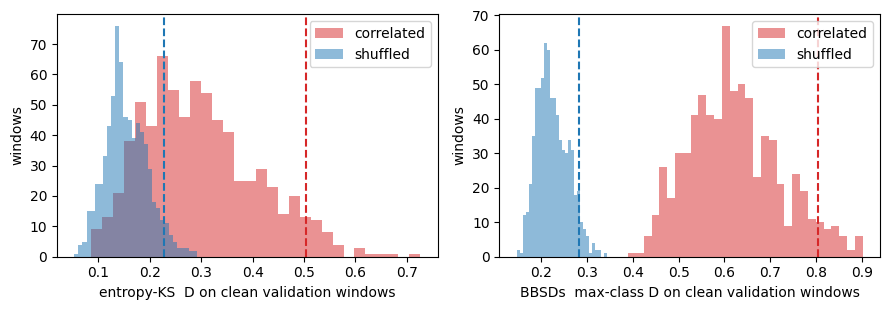

In [ ]:
calib_parts = []
for order in ["correlated", "shuffled"]:
    for s in range(CFG["n_calib_streams"]):
        st = make_stream(TRACKS["calib"], SCHEDULES["E1_clean"], seed=10_000 + s, order=order)
        calib_parts.append(pd.DataFrame({"order": order, "stream": s, **score_stream(st)}))
calib_df = pd.concat(calib_parts, ignore_index=True)
calib_df.to_csv(f"{ART}/calibration_scores.csv", index=False)
del st

TAU = {det: {order: float(calib_df.loc[calib_df.order == order, det].quantile(CFG["tau_quantile"]))
             for order in ["correlated", "shuffled"]} for det in ["entropy", "bbsds"]}

calib_rows = []
for det in ["entropy", "bbsds"]:
    for order in ["correlated", "shuffled"]:
        d = calib_df[calib_df.order == order]
        calib_rows.append({"detector": det, "order": order, "tau": TAU[det][order],
                           "mean_clean_score": d[det].mean(),
                           "nominal_p<0.05_alarm_rate_%": 100 * (d[f"{det}_p"] < 0.05).mean(),
                           "windows": len(d)})
calib_summary = pd.DataFrame(calib_rows).round(4)
calib_summary.to_csv(f"{ART}/calibration_summary.csv", index=False)
print(calib_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, det, name in zip(axes, ["entropy", "bbsds"], ["entropy-KS  D", "BBSDs  max-class D"]):
    for order, color in [("correlated", "tab:red"), ("shuffled", "tab:blue")]:
        ax.hist(calib_df.loc[calib_df.order == order, det], bins=30, alpha=0.5, color=color, label=order)
        ax.axvline(TAU[det][order], color=color, ls="--")
    ax.set_xlabel(f"{name} on clean validation windows")
    ax.set_ylabel("windows")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{ART}/fig_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Gate, adapters and policies
* **Gate**: it opens after *m* consecutive windows with *D* > τ and closes after *k* consecutive windows with *D* ≤ τ. On closing, the deployed model is restored to the source weights, and the optimizer state is rebuilt from scratch.
* **TENT**: one entropy-minimisation step per window on the BatchNorm affine parameters. BatchNorm uses the test-batch statistics, and the window is predicted in the same forward pass.
* **BN baseline**: no gradients. BatchNorm running statistics are updated with momentum 0.1, rather than replaced by each small batch.

**Pilot 5** (after the next cell) checks that `reset()` really restores the exact source checkpoint.

In [ ]:
class PersistenceGate:
    def __init__(self, tau, m, k):
        self.tau, self.m, self.k = tau, m, k
        self.open, self.alarms, self.quiet = False, 0, 0

    def update(self, score):
        """Returns (adapt_now, just_closed)."""
        alarm = score > self.tau
        just_closed = False
        if not self.open:
            self.alarms = self.alarms + 1 if alarm else 0
            if self.alarms >= self.m:
                self.open, self.quiet = True, 0
        else:
            self.quiet = 0 if alarm else self.quiet + 1
            if self.quiet >= self.k:
                self.open, self.alarms, just_closed = False, 0, True
        return self.open, just_closed

def softmax_entropy(logits):
    return -(logits.softmax(1) * logits.log_softmax(1)).sum(1)

class TentAdapter:
    def __init__(self, source, lr):
        self.source, self.lr = source, lr
        self.reset()

    def reset(self):
        # A fresh copy of the source weights and a fresh optimizer: nothing from the last shift survives.
        self.model = copy.deepcopy(self.source).train().requires_grad_(False)
        params = []
        for mod in self.model.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.track_running_stats = False
                mod.running_mean, mod.running_var = None, None
                mod.weight.requires_grad_(True)
                mod.bias.requires_grad_(True)
                params += [mod.weight, mod.bias]
        self.opt = torch.optim.Adam(params, lr=self.lr, betas=(0.9, 0.999))
        self.steps = 0

    def step(self, x):
        logits = self.model(x)
        loss = softmax_entropy(logits).mean()
        self.opt.zero_grad()
        loss.backward()
        self.opt.step()
        self.steps += 1
        return logits.detach()

    @torch.no_grad()
    def predict(self, x):
        # Until the first update the deployed model is exactly the source model.
        return self.source(x) if self.steps == 0 else self.model(x)

class BNStatsAdapter:
    def __init__(self, source, momentum):
        self.source, self.momentum = source, momentum
        self.reset()

    def reset(self):
        self.model = copy.deepcopy(self.source).eval()
        for mod in self.model.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.momentum = self.momentum
        self.steps = 0

    @torch.no_grad()
    def step(self, x):
        for mod in self.model.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.train()
        self.model(x)  # moving-average update of the running statistics
        self.model.eval()
        self.steps += 1
        return self.model(x)

    @torch.no_grad()
    def predict(self, x):
        return self.model(x)

# Pilot 5: adapt on a few dark validation windows, reset, and compare with the source checkpoint.
source_state = {k: v.detach().clone() for k, v in source_model.state_dict().items()}

def max_diff_from_source(model):
    sd = model.state_dict()
    return max((sd[k].float() - v.float()).abs().max().item() for k, v in source_state.items() if k in sd)

pilot = make_stream(TRACKS["calib"], piecewise((1.0, "tunnel", S)), seed=123)
for name, adapter in [("TENT", TentAdapter(source_model, CFG["tent_lr"])),
                      ("BN", BNStatsAdapter(source_model, CFG["bn_momentum"]))]:
    for w in range(5):
        adapter.step(to_input(pilot["x"][w]))
    drift = max_diff_from_source(adapter.model)
    adapter.reset()
    after = max_diff_from_source(adapter.model)
    x0 = to_input(pilot["x"][0])
    same_output = torch.equal(adapter.predict(x0), source_model(x0))
    opt_empty = len(adapter.opt.state) == 0 if name == "TENT" else True
    print(f"Pilot 5 [{name}]: max change after 5 steps {drift:.2e} | after reset {after:.1e} | "
          f"outputs identical to source: {same_output} | optimizer state empty: {opt_empty}")
    assert after == 0 and adapter.steps == 0 and same_output and opt_empty
del pilot

Pilot 5 [TENT]: max change after 5 steps 5.01e-03 | after reset 0.0e+00 | outputs identical to source: True | optimizer state empty: True
Pilot 5 [BN]: max change after 5 steps 3.03e+01 | after reset 0.0e+00 | outputs identical to source: True | optimizer state empty: True


In [ ]:
POLICIES = ["never", "always_tent", "gated_tent", "gated_bn", "oracle_tent"]
CC = CFG["collapse"]

def run_policy(stream, scores, policy, tau=None, m=None, k=None):
    adapter = (BNStatsAdapter(source_model, CFG["bn_momentum"]) if policy == "gated_bn"
               else TentAdapter(source_model, CFG["tent_lr"]))
    gate = PersistenceGate(tau, m, k) if policy.startswith("gated") else None
    n = len(stream["y"])
    acc, adapted = np.zeros(n), np.zeros(n, dtype=bool)
    preds = np.zeros_like(stream["y"])
    resets, collapse, prev_cond = 0, 0, "clean"

    for w in range(n):
        cond = stream["cond"][w]
        if policy == "never":
            adapt = False
        elif policy == "always_tent":
            adapt = True
        elif policy == "oracle_tent":
            # The oracle knows the true boundaries and resets as soon as the condition it adapted to ends.
            if adapter.steps > 0 and cond != prev_cond:
                adapter.reset()
                resets += 1
            adapt = cond != "clean"
        else:
            adapt, just_closed = gate.update(scores[w])
            if just_closed:
                adapter.reset()
                resets += 1

        x = to_input(stream["x"][w])
        logits = adapter.step(x) if adapt else adapter.predict(x)
        p, y = logits.argmax(1).cpu().numpy(), stream["y"][w]
        preds[w], acc[w], adapted[w] = p, (p == y).mean(), adapt

        # Collapse = predictions far more concentrated than the true labels AND low accuracy.
        # (High concentration alone is normal here: a correlated window only holds 2-3 signs.)
        if adapt:
            excess = np.bincount(p).max() / W - np.bincount(y).max() / W
            if excess >= CC["excess_concentration"] and acc[w] < CC["max_acc"]:
                collapse += 1
        prev_cond = cond

    return {"acc": acc, "adapted": adapted, "preds": preds, "resets": resets, "collapse": collapse}

def runs_of(mask):
    """(start, end) of every contiguous run of True values."""
    d = np.diff(np.r_[0, np.asarray(mask, dtype=int), 0])
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))

def summarise(stream, run, policy):
    shifted, acc, adapted = stream["shifted"], run["acc"], run["adapted"]
    clean = ~shifted
    first_shift = int(np.argmax(shifted)) if shifted.any() else len(acc)
    post = clean & (np.arange(len(acc)) > first_shift)
    out = {
        "overall_acc": 100 * acc.mean(),
        "clean_acc": 100 * acc[clean].mean() if clean.any() else np.nan,
        "shift_acc": 100 * acc[shifted].mean() if shifted.any() else np.nan,
        "post_shift_clean_acc": 100 * acc[post].mean() if post.any() else np.nan,
        "worst_window_acc": 100 * acc.min(),
        "macro_f1": 100 * f1_score(stream["y"].ravel(), run["preds"].ravel(), average="macro", zero_division=0),
        "adapt_steps": int(adapted.sum()),
        "clean_windows_adapted": int((adapted & clean).sum()),
        "resets": run["resets"],
        "collapse_windows": run["collapse"],
        "false_alarms": np.nan, "fa_per_1k_clean_frames": np.nan,
        "detection_delay_windows": np.nan, "missed_shifts": np.nan,
    }
    if policy.startswith("gated") or policy == "oracle_tent":
        opens = adapted & ~np.r_[False, adapted[:-1]]
        out["false_alarms"] = int((opens & clean).sum())
        out["fa_per_1k_clean_frames"] = 1000 * out["false_alarms"] / max(1, clean.sum() * W)
        delays, missed = [], 0
        for s, e in runs_of(shifted):
            hits = np.where(adapted[s:e])[0]
            if len(hits):
                delays.append(hits[0])
            else:
                missed += 1
        out["detection_delay_windows"] = np.mean(delays) if delays else np.nan
        out["missed_shifts"] = missed
    return out

def fmt_table(df, keys, cols, digits=1):
    """mean ± std over stream seeds."""
    g = df.groupby(keys, sort=False)[cols]
    mean, std = g.mean(), g.std().fillna(0)
    out = mean.astype(object)
    for c in cols:
        out[c] = ["—" if np.isnan(a) else f"{a:.{digits}f} ± {b:.{digits}f}" for a, b in zip(mean[c], std[c])]
    return out

## 7. Choosing the gate's persistence (m, k) on validation, then freezing everything
The (m, k) grid is evaluated with gated TENT on validation streams built from the calibration tracks (clean, tunnel bursts and fog bursts). The best setting by mean online accuracy is kept. τ, m, k and every other setting are then written to `config.json` **before** any test stream is built.

In [ ]:
tau_e = TAU["entropy"]["correlated"]
val_streams = []
for name in ["E1_clean", "E2_tunnel_bursts", "E3_fog_bursts"]:
    for s in CFG["stream_seeds"]:
        st = make_stream(TRACKS["calib"], SCHEDULES[name], seed=20_000 + s)
        val_streams.append((name, s, st, score_stream(st)))

sel_rows = []
for m, k in CFG["gate_grid"]:
    for name, s, st, sc in val_streams:
        run = run_policy(st, sc["entropy"], "gated_tent", tau_e, m, k)
        sel_rows.append({"m": m, "k": k, "stream": name, "seed": s, **summarise(st, run, "gated_tent")})
sel_df = pd.DataFrame(sel_rows)
sel_summary = (sel_df.groupby(["m", "k"])[["overall_acc", "clean_acc", "shift_acc", "false_alarms", "adapt_steps"]]
               .mean().round(2))
sel_summary.to_csv(f"{ART}/gate_selection_validation.csv")
print(sel_summary)

M, K = map(int, sel_summary.overall_acc.idxmax())
del val_streams

CFG["tau"] = TAU
CFG["gate_m"], CFG["gate_k"] = M, K
with open(f"{ART}/config.json", "w") as f:
    json.dump(CFG, f, indent=2)
print(f"\nFrozen before testing: tau_entropy = {tau_e:.4f}, tau_bbsds = {TAU['bbsds']['correlated']:.4f}, "
      f"m = {M}, k = {K}, TENT lr = {CFG['tent_lr']}")

     overall_acc  clean_acc  shift_acc  false_alarms  adapt_steps
m k                                                              
1 1        88.40      96.80      69.04          0.89         5.33
  2        85.67      94.12      65.98          0.89         9.33
  3        83.54      91.57      64.32          0.78        12.67
2 1        89.44      97.64      70.04          0.11         1.33
  2        88.66      96.57      69.63          0.11         3.22
  3        88.29      96.08      69.40          0.11         4.22
3 1        89.86      97.82      70.85          0.00         0.22
  2        89.54      97.20      70.91          0.00         1.00
  3        89.47      97.07      70.91          0.00         1.22

Frozen before testing: tau_entropy = 0.5038, tau_bbsds = 0.8047, m = 3, k = 1, TENT lr = 0.001


## 8. Core experiments E1–E5 on held-out test streams
Each experiment is run on 3 stream realisations (seeds 0–2). Every policy sees exactly the same windows, so the comparison is paired. The detector is entropy-KS, with the frozen τ, m and k.

In [ ]:
_score_cache = {}

def test_stream(exp, seed, order="correlated"):
    assert "tau" in CFG, "thresholds must be frozen before touching test streams"
    st = make_stream(TRACKS["test"], SCHEDULES[exp], seed=seed, order=order)
    key = (exp, seed, order)
    if key not in _score_cache:
        _score_cache[key] = score_stream(st)
    return st, _score_cache[key]

core_rows, timelines = [], {}
for exp in SCHEDULES:
    for s in CFG["stream_seeds"]:
        st, sc = test_stream(exp, s)
        for pol in POLICIES:
            run = run_policy(st, sc["entropy"], pol, tau_e, M, K)
            core_rows.append({"experiment": exp, "seed": s, "policy": pol, **summarise(st, run, pol)})
            if s == CFG["stream_seeds"][0]:
                tl = timelines.setdefault(exp, {"cond": st["cond"], "sev": st["sev"], "entropy": sc["entropy"],
                                                "bbsds": sc["bbsds"], "runs": {}})
                tl["runs"][pol] = run
        del st
    print(f"{exp} done")

core_df = pd.DataFrame(core_rows)
core_df.to_csv(f"{ART}/core_results_per_seed.csv", index=False)

ACC_COLS = ["overall_acc", "clean_acc", "shift_acc", "post_shift_clean_acc", "worst_window_acc", "macro_f1"]
COST_COLS = ["adapt_steps", "clean_windows_adapted", "false_alarms", "fa_per_1k_clean_frames",
             "detection_delay_windows", "missed_shifts", "resets", "collapse_windows"]
core_acc = fmt_table(core_df, ["experiment", "policy"], ACC_COLS)
core_cost = fmt_table(core_df, ["experiment", "policy"], COST_COLS)
core_df.groupby(["experiment", "policy"], sort=False)[ACC_COLS + COST_COLS].agg(["mean", "std"]).round(3) \
       .to_csv(f"{ART}/core_results_summary.csv")
print("Accuracy (%) - mean ± std over 3 streams\n", core_acc, "\n")
print("Cost / detection - mean ± std over 3 streams\n", core_cost)

e1 = core_df[core_df.experiment == "E1_clean"].groupby("policy").clean_acc.mean()
print(f"\nPilot 3: clean-only stream accuracy - never {e1['never']:.2f}% vs always TENT {e1['always_tent']:.2f}%")

E1_clean done
E2_tunnel_bursts done
E3_fog_bursts done
E4_recovery done
E5_slow_fog done
Accuracy (%) - mean ± std over 3 streams
                              overall_acc   clean_acc   shift_acc post_shift_clean_acc worst_window_acc    macro_f1
experiment       policy                                                                                           
E1_clean         never        94.1 ± 0.0  94.1 ± 0.0           —                    —       49.0 ± 3.6  90.4 ± 0.0
                 always_tent  66.2 ± 1.8  66.2 ± 1.8           —                    —       13.5 ± 4.5  54.1 ± 1.4
                 gated_tent   93.9 ± 0.2  93.9 ± 0.2           —                    —       49.0 ± 3.6  90.3 ± 0.2
                 gated_bn     94.1 ± 0.0  94.1 ± 0.0           —                    —       49.0 ± 3.6  90.4 ± 0.0
                 oracle_tent  94.1 ± 0.0  94.1 ± 0.0           —                    —       49.0 ± 3.6  90.4 ± 0.0
E2_tunnel_bursts never        84.8 ± 1.0  92.5 ± 1.1  74.3 ± 2.9

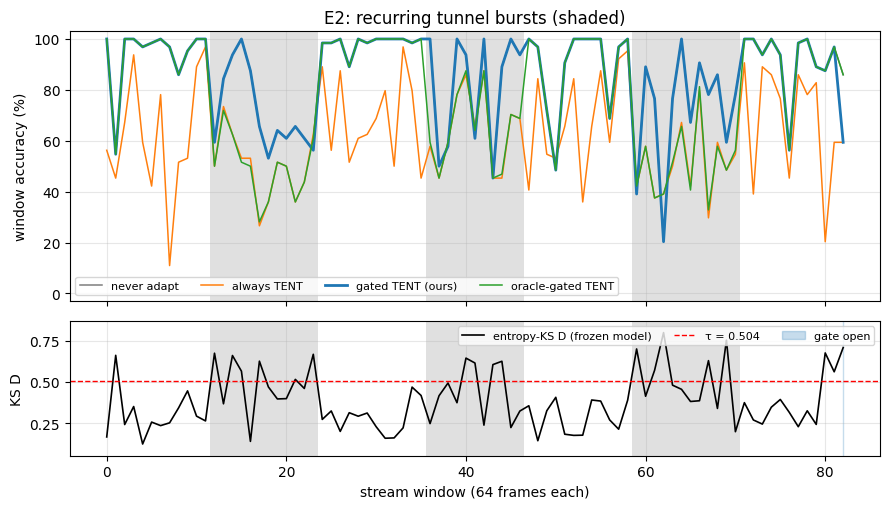

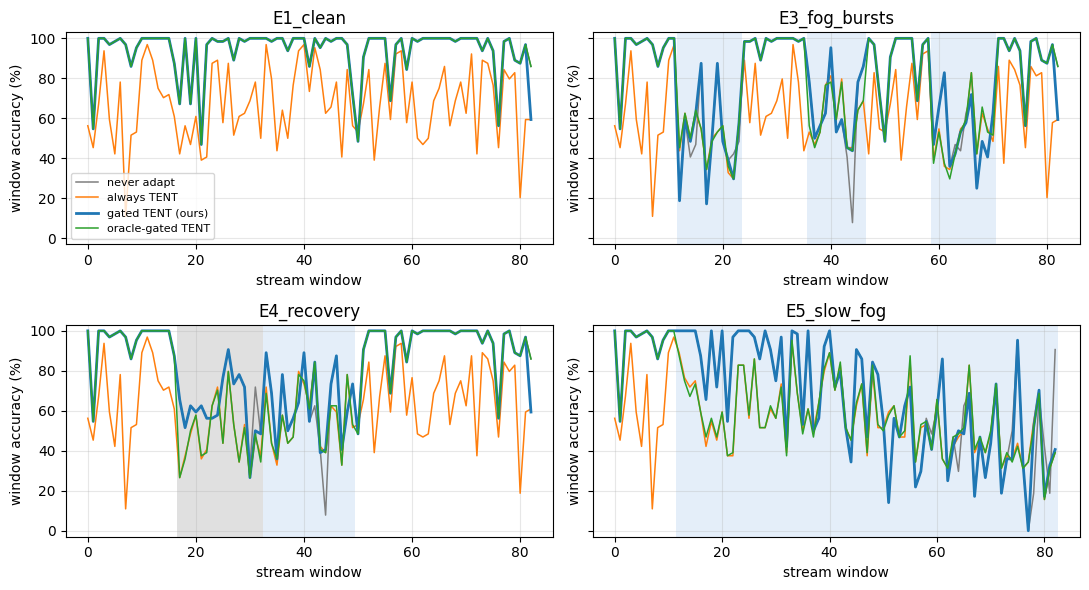

In [ ]:
COLORS = {"never": "#7f7f7f", "always_tent": "#ff7f0e", "gated_tent": "#1f77b4",
          "gated_bn": "#9467bd", "oracle_tent": "#2ca02c"}
LABELS = {"never": "never adapt", "always_tent": "always TENT", "gated_tent": "gated TENT (ours)",
          "gated_bn": "gated BN", "oracle_tent": "oracle-gated TENT"}
SHADE = {"tunnel": "#303030", "fog": "#4a90d9"}

def shade(ax, cond):
    for name, color in SHADE.items():
        for s, e in runs_of(cond == name):
            ax.axvspan(s - 0.5, e - 0.5, color=color, alpha=0.15, lw=0)

def plot_accuracy(ax, exp, policies=("never", "always_tent", "gated_tent", "oracle_tent")):
    tl = timelines[exp]
    x = np.arange(len(tl["cond"]))
    shade(ax, tl["cond"])
    for pol in policies:
        ax.plot(x, 100 * tl["runs"][pol]["acc"], color=COLORS[pol], label=LABELS[pol],
                lw=2.0 if pol == "gated_tent" else 1.1)
    ax.set_ylim(-3, 103)
    ax.set_ylabel("window accuracy (%)")
    ax.grid(alpha=0.3)

# Main figure: accuracy over time on E2 together with the detector score and gate state.
tl = timelines["E2_tunnel_bursts"]
x = np.arange(len(tl["cond"]))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
plot_accuracy(a1, "E2_tunnel_bursts")
a1.legend(ncol=4, fontsize=8, loc="lower left")
a1.set_title("E2: recurring tunnel bursts (shaded)")
shade(a2, tl["cond"])
a2.plot(x, tl["entropy"], color="black", lw=1.2, label="entropy-KS D (frozen model)")
a2.axhline(tau_e, color="red", ls="--", lw=1, label=f"τ = {tau_e:.3f}")
a2.fill_between(x, 0, 1, where=tl["runs"]["gated_tent"]["adapted"], step="mid", alpha=0.25,
                color=COLORS["gated_tent"], transform=a2.get_xaxis_transform(), label="gate open")
a2.set_xlabel(f"stream window ({W} frames each)")
a2.set_ylabel("KS D")
a2.legend(ncol=3, fontsize=8, loc="upper right")
a2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{ART}/fig_e2_accuracy_over_time.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for ax, exp in zip(axes.ravel(), ["E1_clean", "E3_fog_bursts", "E4_recovery", "E5_slow_fog"]):
    plot_accuracy(ax, exp)
    ax.set_title(exp)
    ax.set_xlabel("stream window")
axes[0, 0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(f"{ART}/fig_e1_e3_e4_e5_accuracy_over_time.png", dpi=200, bbox_inches="tight")
plt.show()

tl_rows = []
for exp, tl in timelines.items():
    for w in range(len(tl["cond"])):
        r = {"experiment": exp, "window": w, "condition": tl["cond"][w], "severity": tl["sev"][w],
             "entropy_D": tl["entropy"][w], "bbsds_D": tl["bbsds"][w]}
        for pol, run in tl["runs"].items():
            r[f"acc_{pol}"] = 100 * run["acc"][w]
            r[f"adapting_{pol}"] = int(run["adapted"][w])
        tl_rows.append(r)
pd.DataFrame(tl_rows).to_csv(f"{ART}/timelines_seed0.csv", index=False)

## 9. Ablations
1. **Detector × stream order**: entropy-KS vs. BBSDs, on correlated and shuffled versions of the same test frames. Each ordering uses its own τ calibrated on validation. We report raw window-level alarm rates and the outcome when each detector drives the gate.
2. **Stream order × policy**: does always-on TENT hurt because of correlation?
3. **Gate persistence (m, k)** on E2. This is a sensitivity check only; m and k were already fixed on validation.

In [ ]:
det_rows, order_rows = [], []
for order in ["correlated", "shuffled"]:
    for exp in ["E1_clean", "E2_tunnel_bursts", "E3_fog_bursts"]:
        for s in CFG["stream_seeds"]:
            st, sc = test_stream(exp, s, order)
            shifted = st["shifted"]
            for det in ["entropy", "bbsds"]:
                tau = TAU[det][order]
                alarm = sc[det] > tau
                run = run_policy(st, sc[det], "gated_tent", tau, M, K)
                det_rows.append({"order": order, "experiment": exp, "detector": det, "seed": s,
                                 "clean_alarm_rate": 100 * alarm[~shifted].mean(),
                                 "shift_alarm_rate": 100 * alarm[shifted].mean() if shifted.any() else np.nan,
                                 "nominal_p05_clean_alarm_rate": 100 * (sc[f"{det}_p"][~shifted] < 0.05).mean(),
                                 **summarise(st, run, "gated_tent")})
            for pol in ["never", "always_tent", "gated_tent", "oracle_tent"]:
                run = run_policy(st, sc["entropy"], pol, TAU["entropy"][order], M, K)
                order_rows.append({"order": order, "experiment": exp, "policy": pol, "seed": s,
                                   **summarise(st, run, pol)})
            del st
    print(f"{order} streams done")

det_df, order_df = pd.DataFrame(det_rows), pd.DataFrame(order_rows)
det_df.to_csv(f"{ART}/ablation_detector_per_seed.csv", index=False)
order_df.to_csv(f"{ART}/ablation_order_per_seed.csv", index=False)

det_table = fmt_table(det_df, ["order", "experiment", "detector"],
                      ["clean_alarm_rate", "shift_alarm_rate", "nominal_p05_clean_alarm_rate", "overall_acc",
                       "clean_acc", "shift_acc", "false_alarms", "detection_delay_windows", "missed_shifts"])
order_table = fmt_table(order_df, ["experiment", "order", "policy"], ["overall_acc", "clean_acc", "shift_acc"])
print("Detector comparison (gated TENT driven by each detector)\n", det_table, "\n")
print("Correlated vs shuffled streams (entropy-KS gate)\n", order_table)

correlated streams done
shuffled streams done
Detector comparison (gated TENT driven by each detector)
                                      clean_alarm_rate shift_alarm_rate nominal_p05_clean_alarm_rate overall_acc   clean_acc   shift_acc false_alarms detection_delay_windows missed_shifts
order      experiment       detector                                                                                                                                                      
correlated E1_clean         entropy         6.8 ± 1.4                —                   90.8 ± 0.7  93.9 ± 0.2  93.9 ± 0.2           —    0.3 ± 0.6                       —     0.0 ± 0.0
                            bbsds           7.2 ± 3.6                —                  100.0 ± 0.0  94.1 ± 0.0  94.1 ± 0.0           —    0.0 ± 0.0                       —     0.0 ± 0.0
           E2_tunnel_bursts entropy         7.6 ± 3.2       40.0 ± 4.9                   91.7 ± 3.6  84.6 ± 1.0  92.3 ± 0.8  74.0 ± 3.1    0.3 ± 0.6

In [ ]:
mk_rows = []
for s in CFG["stream_seeds"]:
    st, sc = test_stream("E2_tunnel_bursts", s)
    for m, k in CFG["gate_grid"]:
        run = run_policy(st, sc["entropy"], "gated_tent", tau_e, m, k)
        mk_rows.append({"m": m, "k": k, "seed": s, **summarise(st, run, "gated_tent")})
    del st
mk_df = pd.DataFrame(mk_rows)
mk_df.to_csv(f"{ART}/ablation_gate_mk_per_seed.csv", index=False)
mk_table = fmt_table(mk_df, ["m", "k"], ["overall_acc", "clean_acc", "shift_acc", "adapt_steps",
                                         "false_alarms", "detection_delay_windows", "resets"])
print(f"Gate persistence on E2 (selected on validation: m={M}, k={K})\n", mk_table)

Gate persistence on E2 (selected on validation: m=3, k=1)
     overall_acc   clean_acc   shift_acc adapt_steps false_alarms detection_delay_windows      resets
m k                                                                                                 
1 1  80.6 ± 1.7  90.2 ± 1.3  67.4 ± 2.3  17.7 ± 1.2    3.0 ± 1.7               2.4 ± 1.0  11.3 ± 2.1
  2  77.4 ± 1.9  88.1 ± 2.8  62.7 ± 2.6  29.0 ± 2.6    3.0 ± 1.7               2.4 ± 1.0   7.0 ± 1.7
  3  75.7 ± 2.5  86.2 ± 4.3  61.4 ± 3.0  36.0 ± 3.6    3.0 ± 1.7               1.9 ± 1.0   7.0 ± 1.7
2 1  83.5 ± 1.1  92.0 ± 0.7  71.8 ± 3.6   6.0 ± 2.0    0.3 ± 0.6               5.1 ± 1.5   3.7 ± 0.6
  2  82.0 ± 0.5  91.8 ± 1.0  68.6 ± 2.7  11.3 ± 2.9    0.3 ± 0.6               5.1 ± 1.5   2.7 ± 0.6
  3  81.3 ± 0.3  91.7 ± 1.2  67.1 ± 2.3  14.0 ± 3.5    0.3 ± 0.6               5.1 ± 1.5   2.7 ± 0.6
3 1  84.6 ± 1.0  92.3 ± 0.8  74.0 ± 3.1   2.0 ± 1.7    0.3 ± 0.6               6.8 ± 2.5   1.0 ± 1.0
  2  84.0 ± 1.3  92.1 ± 1.2  72.